In [35]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from fdm_solver import State

In [36]:
""" Plotting function """
def plot_initial(state):
    fig = plt.figure(2)
    ax = fig.add_axes([0.20, 0.18, 0.79, 0.81])
    ax.plot(state.x / L, state.u_initial, linewidth=2, color="black",
            linestyle="solid", label=r"t = 0", zorder=1)
    ax.set_xlabel(r"$x / L$", fontsize=18)
    ax.set_ylabel(r"$u$", fontsize=18)
    ax.set_xlim(-0.5, 0.5)
    ax.set_xticks([-0.5, -0.25, 0, 0.25, 0.5])
    ax.set_xticklabels([-0.5, -0.25, 0, 0.25, 0.5])
    ax.tick_params(axis="both", labelsize=14)
    ax.yaxis.set_major_locator(MaxNLocator(nbins=6))
    ax.legend(loc="best", frameon=False, fontsize=14)
    plt.show()


def plot_solution(state):
    colors = ["red", "blue", "green", "orange"]
    fig = plt.figure(2)
    ax = fig.add_axes([0.20, 0.18, 0.79, 0.81])
    ax.plot(state.x / L, state.u_initial, linewidth=2, color="black",
            linestyle="solid", label=r"t = 0", zorder=1)
    for itr, t in enumerate([10, 20, 50, 100]):
        ax.plot(state.x / state.L, state.u[t], linewidth=2,
                color=colors[itr], linestyle="solid",
                label=r"t = " + str(t), zorder=1)
    ax.set_xlabel(r"$x / L$", fontsize=18)
    ax.set_ylabel(r"$u$", fontsize=18)
    ax.set_xlim(-0.5, 0.5)
    ax.set_xticks([-0.5, -0.25, 0, 0.25, 0.5])
    ax.set_xticklabels([-0.5, -0.25, 0, 0.25, 0.5])
    ax.tick_params(axis="both", labelsize=14)
    ax.yaxis.set_major_locator(MaxNLocator(nbins=6))
    ax.legend(loc="best", frameon=False, fontsize=14)
    plt.show()

# Create various training data-sets

### A Gaussian initialization

In [37]:
def gaussian_func(x, mu, sigma):
    return 1 / np.sqrt(2 * np.pi * sigma**2) * np.exp(
        -(x - mu)**2 / (2 * sigma**2)
    )

In [38]:
L = 200
state = State(L)
state.initialize(gaussian_func, (0, 8))
iterations = 100
D = 0.4
state.evolve(iterations, D)

Solving system in time
Chosen Fourier number: 0.4 <= 0.5
Stable discretization!
Solution complete!


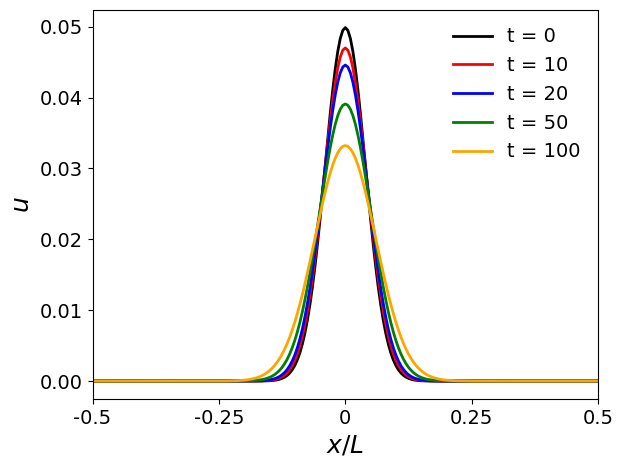

In [39]:
plot_solution(state)

### A uniform block initialization

In [40]:
def uniform_func(x, mu, l):
    return np.where(np.abs(x - mu) < l/2, 1/l, 0)

In [41]:
state = State(L)
state.initialize(uniform_func, (0, L/2))
iterations = 100
D = 0.4
state.evolve(iterations, D)

Solving system in time
Chosen Fourier number: 0.4 <= 0.5
Stable discretization!
Solution complete!


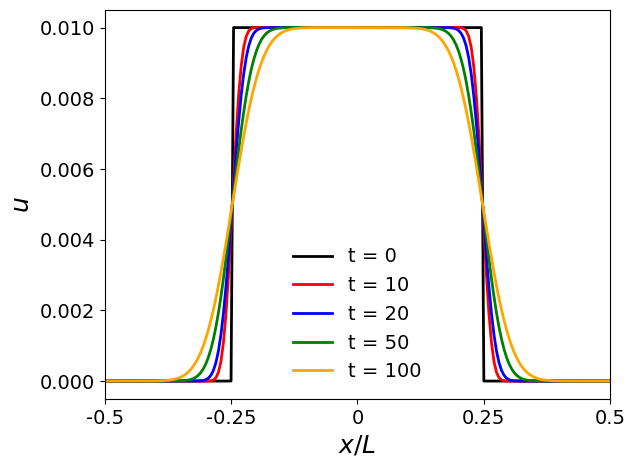

In [42]:
plot_solution(state)

### A cosine initialization

In [43]:
def cosine_func(x, mu, l, n):
    return np.where(np.abs(x - mu) < l/2, np.cos(n * np.pi * (x - mu) / l), 0)

In [44]:
n = 1
state = State(L)
state.initialize(cosine_func, (-L/4, L/4, n))
iterations = 100
D = 0.4
state.evolve(iterations, D)

Solving system in time
Chosen Fourier number: 0.4 <= 0.5
Stable discretization!
Solution complete!


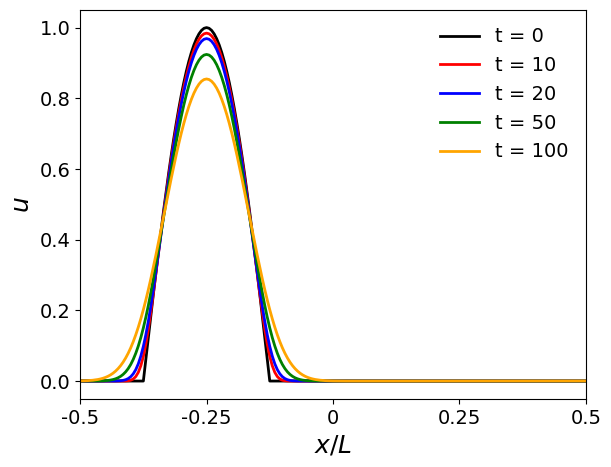

In [45]:
plot_solution(state)

In [46]:
from data_generator import create_params, generate_data

In [47]:
params_dict = {
    "mu": (-L/4, L/4, 5),
    "l": (L/16, L/4, 5),
    "n": (1, 5, 5)
}
params = create_params(params_dict)

In [48]:
print(params[-1])
state = State(L)
state.initialize(cosine_func, params[-1])
iterations = 100
D = 0.4
state.evolve(iterations, D)

[50. 50.  5.]
Solving system in time
Chosen Fourier number: 0.4 <= 0.5
Stable discretization!
Solution complete!


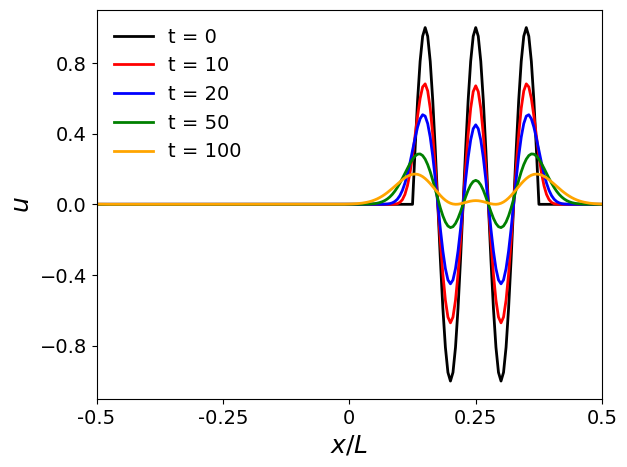

In [49]:
plot_solution(state)

In [50]:
training_range = (0, 10)
validation_range = (60, 61)
training_data, validation_data = generate_data(
    cosine_func,
    params,
    D,
    L,
    iterations,
    training_range,
    validation_range
)